In [1]:
import torch

print("Versi PyTorch:", torch.__version__)
print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))

Versi PyTorch: 2.14.1+cu130
GPU tersedia: True
Nama GPU: Tesla T4


In [2]:
!git clone https://github.com/auliyasalwahayati-web/mpox-skin-lesion-classification-kelompok.git

Cloning into 'mpox-skin-lesion-classification-kelompok'...
remote: Enumerating objects: 55, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (50/50), done.
remote: Total 55 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (55/55), 3.15 MiB | 6.64 MiB/s, done.


In [3]:
%cd /content/mpox-skin-lesion-classification-kelompok/mpox-skin-lesion-classification-kel

/content/mpox-skin-lesion-classification-kelompok/mpox-skin-lesion-classification-kel


In [4]:
!ls

Checkpoints  Models	  README.md	    Results  train.py
config.py    __pycache__  requirements.txt  test.py  Utils


In [5]:
!pip install -q kagglehub opencv-python numpy pandas matplotlib seaborn scikit-learn

In [6]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130


In [15]:
%%writefile Models/EfficientNetB0.py

import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0
from torchvision.models import EfficientNet_B0_Weights


class EfficientNetB0(nn.Module):
    def __init__(self, output=6, pretrained=True):
        super().__init__()

        if pretrained:
            weights = EfficientNet_B0_Weights.DEFAULT
        else:
            weights = None

        self.model = efficientnet_b0(weights=weights)

        # Mengubah output bawaan ImageNet, yaitu 1000 kelas,
        # menjadi 6 kelas sesuai dataset Mpox.
        in_features = self.model.classifier[1].in_features
        self.model.classifier[1] = nn.Linear(in_features, output)

    def forward(self, x):
        x = self.model(x)

        # train.py menggunakan NLLLoss,
        # sehingga output diubah menjadi log-probabilitas.
        return torch.log_softmax(x, dim=1)

Overwriting Models/EfficientNetB0.py


In [16]:
%%writefile config.py

from Models.CNN import SimpleCNN
from Models.CNN2 import SimpleCNNReg
from Models.EfficientNetB0 import EfficientNetB0


CONFIGS = {
    "model1": {
        "model": SimpleCNN,
        "model_args": {
            "output": 6
        },
        "img_size": 100,
        "batch_size": 32,
        "epoch": 100,
        "lr": 0.001,
        "patience": None,
    },

    "model2": {
        "model": SimpleCNNReg,
        "model_args": {
            "output": 6
        },
        "img_size": 100,
        "batch_size": 16,
        "epoch": 20,
        "lr": 0.0001,
        "patience": 5,
    },

    "efficientnetb0": {
        "model": EfficientNetB0,
        "model_args": {
            "output": 6,
            "pretrained": True
        },
        "img_size": 224,
        "batch_size": 16,
        "epoch": 20,
        "lr": 0.0001,
        "patience": 5,
    },
}

Overwriting config.py


In [11]:
from Models.EfficientNetB0 import EfficientNetB0
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

model = EfficientNetB0(
    output=6,
    pretrained=False
).to(device)

dummy_input = torch.rand(2, 3, 224, 224).to(device)
output = model(dummy_input)

print("Device:", device)
print("Bentuk output:", output.shape)
print("Jumlah parameter:", sum(p.numel() for p in model.parameters()))

Device: cuda
Bentuk output: torch.Size([2, 6])
Jumlah parameter: 4015234


In [12]:
!python train.py --model efficientnetb0 --folds 1 --epochs 2

Model: efficientnetb0 | device: cuda | fold: 1-1 | epoch: 2
Using Colab cache for faster access to the 'mpox-skin-lesion-dataset-version-20-msld-v20' dataset.

===== Fold 1 =====
  Data: 7518 train, 144 valid
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100% 20.5M/20.5M [00:00<00:00, 168MB/s]
  Epoch   1/2 | train loss = 0.6164 | valid loss = 0.6159 | valid acc = 0.7708 | 50.8s  <- disimpan
  Epoch   2/2 | train loss = 0.1710 | valid loss = 0.7538 | valid acc = 0.7639 | 48.2s
  Selesai: model terbaik di epoch 1 (valid loss 0.6159), 2.5 menit

Selesai. Model di Checkpoints/efficientnetb0/, grafik dan riwayat di Results/efficientnetb0/


In [18]:
!python test.py --model efficientnetb0 --folds 1

Model: efficientnetb0 | device: cuda | fold: 1-1
Using Colab cache for faster access to the 'mpox-skin-lesion-dataset-version-20-msld-v20' dataset.

===== Fold 1 =====
  Data: 74 test
  Model: Checkpoints/efficientnetb0/efficientnetb0_fold1.pt (epoch 1)
  Confusion matrix (baris = label asli, kolom = prediksi):
[[ 8  0  0  0  0  1]
 [ 0  5  1  0  0  1]
 [ 0  0 15  0  1  0]
 [ 0  0  0  9  0  0]
 [ 0  0  0  1  5  0]
 [ 3  2  1  5  0 16]]
  accuracy = 0.7838 | precision = 0.7744 | recall = 0.8278 | f1 = 0.7863 | roc_auc = 0.9687

===== Rata-rata 1 fold =====
  accuracy  = 0.7838 ± 0.0000
  precision = 0.7744 ± 0.0000
  recall    = 0.8278 ± 0.0000
  f1        = 0.7863 ± 0.0000
  roc_auc   = 0.9687 ± 0.0000

Selesai. Metrik di Results/efficientnetb0/test_metrics.csv, confusion matrix di Results/efficientnetb0/


In [19]:
import pandas as pd

hasil = pd.read_csv(
    "Results/efficientnetb0/test_metrics.csv"
)

hasil

,fold,accuracy,precision,recall,f1,roc_auc
0,fold1,0.783784,0.774356,0.827767,0.786304,0.968651
1,mean,0.783784,0.774356,0.827767,0.786304,0.968651
2,std,0.000000,0.000000,0.000000,0.000000,0.000000


In [20]:
print(
    open(
        "Results/efficientnetb0/classification_report_fold1.txt",
        "r"
    ).read()
)

              precision    recall  f1-score   support

  Chickenpox     0.7273    0.8889    0.8000         9
      Cowpox     0.7143    0.7143    0.7143         7
        HFMD     0.8824    0.9375    0.9091        16
     Healthy     0.6000    1.0000    0.7500         9
     Measles     0.8333    0.8333    0.8333         6
   Monkeypox     0.8889    0.5926    0.7111        27

    accuracy                         0.7838        74
   macro avg     0.7744    0.8278    0.7863        74
weighted avg     0.8117    0.7838    0.7797        74



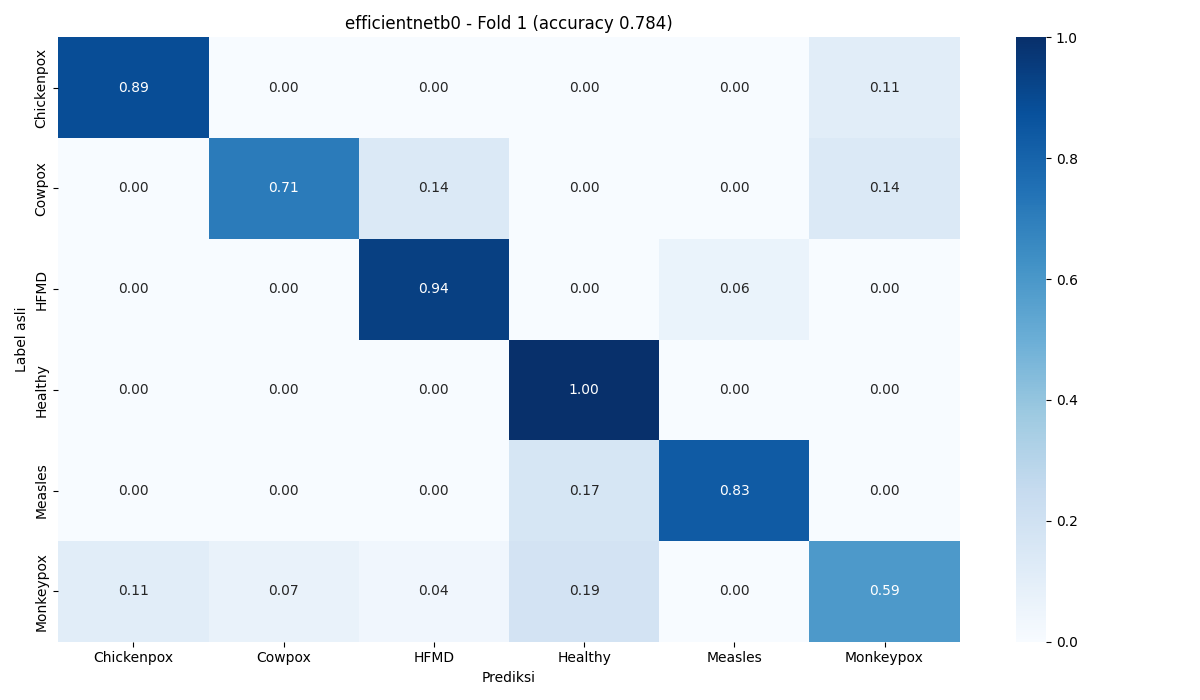

In [21]:
from IPython.display import Image, display

display(
    Image(
        filename="Results/efficientnetb0/confusion_matrix_fold1.png"
    )
)

In [22]:
!python train.py --model efficientnetb0 --folds 5 --epochs 20

Model: efficientnetb0 | device: cuda | fold: 1-5 | epoch: 20
Using Colab cache for faster access to the 'mpox-skin-lesion-dataset-version-20-msld-v20' dataset.

===== Fold 1 =====
  Data: 7518 train, 144 valid
  Epoch   1/20 | train loss = 0.6164 | valid loss = 0.6159 | valid acc = 0.7708 | 51.5s  <- disimpan
  Epoch   2/20 | train loss = 0.1710 | valid loss = 0.7538 | valid acc = 0.7639 | 49.3s
  Epoch   3/20 | train loss = 0.0957 | valid loss = 0.8054 | valid acc = 0.7639 | 49.6s
  Epoch   4/20 | train loss = 0.0627 | valid loss = 0.7736 | valid acc = 0.7847 | 49.7s
  Epoch   5/20 | train loss = 0.0513 | valid loss = 0.7322 | valid acc = 0.7986 | 49.6s
  Epoch   6/20 | train loss = 0.0382 | valid loss = 0.8839 | valid acc = 0.7639 | 49.7s
  Early stopping: valid loss tidak membaik selama 5 epoch
  Selesai: model terbaik di epoch 1 (valid loss 0.6159), 5.2 menit

===== Fold 2 =====
  Data: 7126 train, 164 valid
  Epoch   1/20 | train loss = 0.6760 | valid loss = 0.5375 | valid acc = 0

In [24]:
hasil = pd.read_csv(
    "Results/efficientnetb0/test_metrics.csv"
)

hasil

,fold,accuracy,precision,recall,f1,roc_auc
0,fold1,0.783784,0.774356,0.827767,0.786304,0.968651
1,mean,0.783784,0.774356,0.827767,0.786304,0.968651
2,std,0.000000,0.000000,0.000000,0.000000,0.000000


In [25]:
!python test.py --model efficientnetb0 --folds 5

Model: efficientnetb0 | device: cuda | fold: 1-5
Using Colab cache for faster access to the 'mpox-skin-lesion-dataset-version-20-msld-v20' dataset.

===== Fold 1 =====
  Data: 74 test
  Model: Checkpoints/efficientnetb0/efficientnetb0_fold1.pt (epoch 1)
  Confusion matrix (baris = label asli, kolom = prediksi):
[[ 8  0  0  0  0  1]
 [ 0  5  1  0  0  1]
 [ 0  0 15  0  1  0]
 [ 0  0  0  9  0  0]
 [ 0  0  0  1  5  0]
 [ 3  2  1  5  0 16]]
  accuracy = 0.7838 | precision = 0.7744 | recall = 0.8278 | f1 = 0.7863 | roc_auc = 0.9687

===== Fold 2 =====
  Data: 82 test
  Model: Checkpoints/efficientnetb0/efficientnetb0_fold2.pt (epoch 3)
  Confusion matrix (baris = label asli, kolom = prediksi):
[[ 4  0  0  1  0  6]
 [ 0  3  0  0  0  1]
 [ 0  0 20  0  0  0]
 [ 0  0  1 10  0  0]
 [ 0  0  1  0  4  0]
 [ 4  1  5  2  0 19]]
  accuracy = 0.7317 | precision = 0.7485 | recall = 0.7393 | f1 = 0.7352 | roc_auc = 0.9332

===== Fold 3 =====
  Data: 64 test
  Model: Checkpoints/efficientnetb0/efficientnet

In [26]:
import pandas as pd

hasil = pd.read_csv(
    "Results/efficientnetb0/test_metrics.csv"
)

hasil

,fold,accuracy,precision,recall,f1,roc_auc
0,fold1,0.783784,0.774356,0.827767,0.786304,0.968651
1,fold2,0.731707,0.748457,0.739272,0.735168,0.933166
2,fold3,0.828125,0.810048,0.768434,0.784271,0.961164
3,fold4,0.814815,0.833135,0.845192,0.818267,0.979405
4,fold5,0.841270,0.901023,0.795767,0.825652,0.984037
5,mean,0.799940,0.813404,0.795286,0.789932,0.965285
6,std,0.039091,0.052575,0.038482,0.032010,0.017950


In [27]:
for fold in range(1, 6):
    print(f"\n===== Classification Report Fold {fold} =====")
    print(
        open(
            f"Results/efficientnetb0/classification_report_fold{fold}.txt",
            "r"
        ).read()
    )


===== Classification Report Fold 1 =====
              precision    recall  f1-score   support

  Chickenpox     0.7273    0.8889    0.8000         9
      Cowpox     0.7143    0.7143    0.7143         7
        HFMD     0.8824    0.9375    0.9091        16
     Healthy     0.6000    1.0000    0.7500         9
     Measles     0.8333    0.8333    0.8333         6
   Monkeypox     0.8889    0.5926    0.7111        27

    accuracy                         0.7838        74
   macro avg     0.7744    0.8278    0.7863        74
weighted avg     0.8117    0.7838    0.7797        74


===== Classification Report Fold 2 =====
              precision    recall  f1-score   support

  Chickenpox     0.5000    0.3636    0.4211        11
      Cowpox     0.7500    0.7500    0.7500         4
        HFMD     0.7407    1.0000    0.8511        20
     Healthy     0.7692    0.9091    0.8333        11
     Measles     1.0000    0.8000    0.8889         5
   Monkeypox     0.7308    0.6129    0.6667     

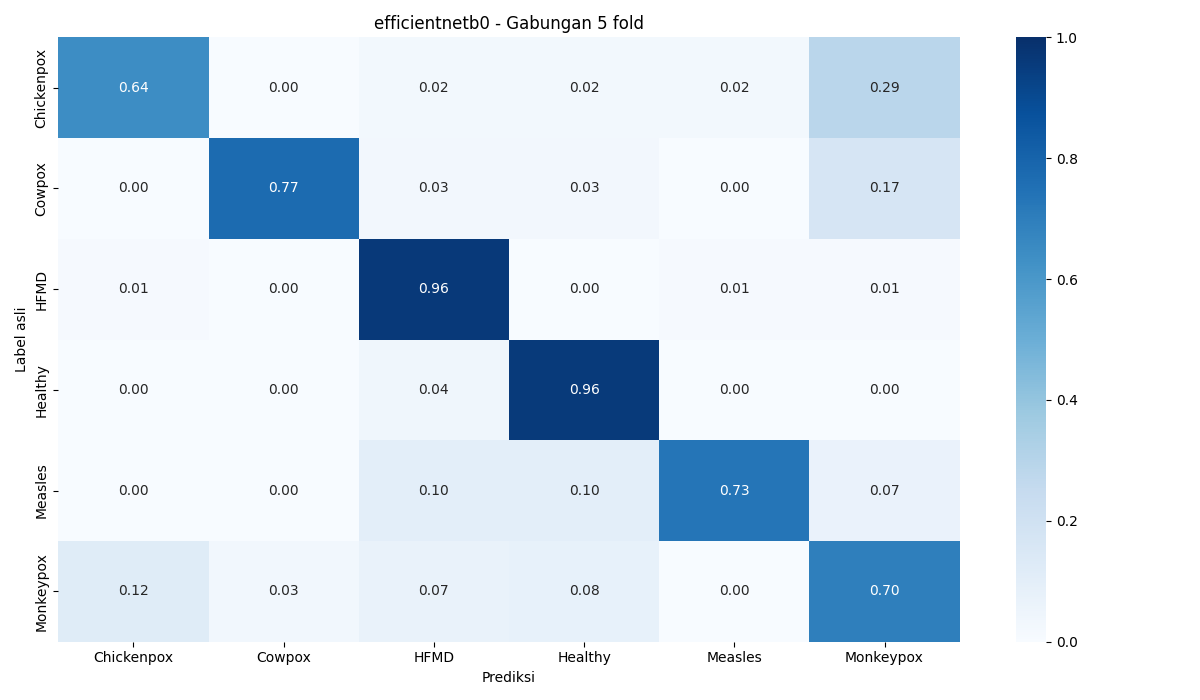

In [28]:
from IPython.display import Image, display

display(
    Image(
        filename="Results/efficientnetb0/confusion_matrix_all.png"
    )
)